In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pip install datasets pandas

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Load data HF
from datasets import load_dataset

dataset = load_dataset("AlekseyKorshuk/quora-question-pairs")

df = dataset["train"].to_pandas()

In [4]:
df.head()

,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,What is the step by step guide to invest in sh...,What is the step by step guide to invest in sh...,0
1,1,3,4,What is the story of Kohinoor (Koh-i-Noor) Dia...,What would happen if the Indian government sto...,0
2,2,5,6,How can I increase the speed of my internet co...,How can Internet speed be increased by hacking...,0
3,3,7,8,Why am I mentally very lonely? How can I solve...,Find the remainder when [math]23^{24}[/math] i...,0
4,4,9,10,"Which one dissolve in water quikly sugar, salt...",Which fish would survive in salt water?,0


In [5]:
df.shape

(404290, 6)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 404290 entries, 0 to 404289
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   id            404290 non-null  int64 
 1   qid1          404290 non-null  int64 
 2   qid2          404290 non-null  int64 
 3   question1     404289 non-null  object
 4   question2     404288 non-null  object
 5   is_duplicate  404290 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 18.5+ MB


In [7]:
df.sample(10)

,id,qid1,qid2,question1,question2,is_duplicate
343853,343853,472022,472023,How can I decrease my weight from 78 kg to 70 ...,"I'm 5""4 and my weight is 70 kg. I want to shed...",0
296830,296830,419107,419108,What are some basic care provided for medical ...,What are some basic cares provided for medical...,0
6354,6354,12453,12454,Should I break up with my girlfriend? What do ...,Should I break up with my girlfriend?,0
21000,21000,39574,39575,What is the use of C++ STL in competitive prog...,What is the best way to learn C++ STL for prog...,0
204712,204712,171481,10997,What is the best feeling in this world?,What are some of the best feelings in life?,1
197903,197903,298981,298982,What colleges should I apply for with a percen...,What are some good colleges to apply for if my...,0
169156,169156,261844,261845,What are some of the most amazing robots?,What is the most interesting robot you ever made?,0
296777,296777,419039,419040,What colors are considered elegant?,I heard that in the past pink was considered a...,0
174531,174531,268951,268952,How do I raise an issue without hurting other'...,Why can't I get any work done?,0
330957,330957,404980,457775,I keep dreaming that my husband is cheating on...,My guy is a cheater but every time I try to br...,0


In [10]:
# Missing Value
df.isnull().sum()

id              0
qid1            0
qid2            0
question1       1
question2       2
is_duplicate    0
dtype: int64

In [8]:
# duplicated row
df.duplicated().sum()

np.int64(0)

is_duplicate
0    255027
1    149263
Name: count, dtype: int64
is_duplicate
0    63.080215
1    36.919785
Name: count, dtype: float64


<Axes: xlabel='is_duplicate'>

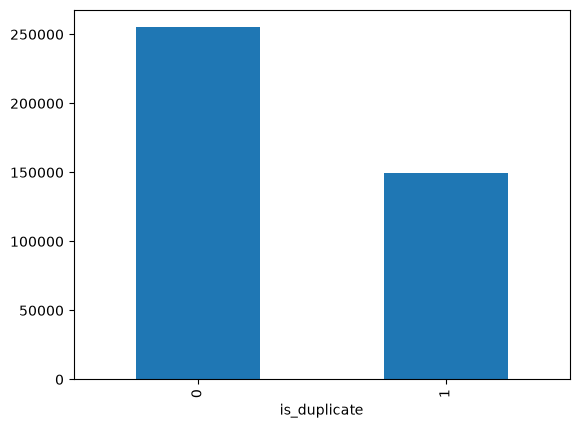

In [11]:
# Distribution of duplicate and non-duplicates question

print(df['is_duplicate'].value_counts())
print((df['is_duplicate'].value_counts()/df['is_duplicate'].count())*100)
df['is_duplicate'].value_counts().plot(kind='bar')

In [12]:
#Repeated question
qid = pd.Series(df['qid1'].tolist() + df['qid2'].tolist())
print('Number of unique questions', np.unique(qid).shape[0])
x = qid.value_counts()>1
print('Number of questions getting repeated', x[x].shape[0])


Number of unique questions 537933
Number of questions getting repeated 111780


findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmti10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


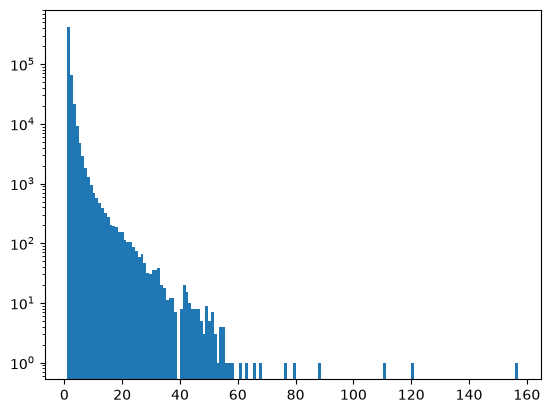

In [13]:

#Repeated question and histogram
plt.hist(qid.value_counts().values,bins=160)
plt.yscale('log')
plt.show()